# UCS420: Cognitive Computing
## Assignment 7 - NLP-I

Name: Kovid Kumar
Roll No: 1024170353
Branch: COPC, Thapar Institute of Engineering and Technology

In [1]:
# imports and nltk downloads
import re, string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

from nltk.tokenize import sent_tokenize, word_tokenize, RegexpTokenizer
from nltk.corpus import stopwords, wordnet as wn
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag, bigrams

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

## Dataset

Roll number 1024170353 gives 15 tickets with fingerprint 042D2609 in the starter notebook. The tickets are copied
below exactly as the starter printed them, so this notebook runs on its own. If process_ticket() and TEST_LINES
from the starter are already defined in the session they are used, otherwise a plain nltk version and a set of
test lines are used (see the comments in the cells).

In [2]:
ROLL_NO = "1024170353"
FINGERPRINT = "042D2609"     # as printed by the starter notebook

tickets = [
    "Ticket #4521 is still open.",
    "The LMS says 'Not Submitted'.",
    "The Python crashes while opening. Is there another solution?",
    "The printer is showing an error. Is there another solution?",
    "I can't login and I didn't change anything.",
    "The projector keeps disconnecting. I don't know what changed.",
    "I am unable to use the server during the lab. It worked yesterday.",
    "I reinstalled the MATLAB when connected to campus Wi-Fi. Please help.",
    "I cannot access the LMS since yesterday. I don't know what changed.",
    "I cannot access the email since yesterday. It works on another computer.",
    "Lms failed to open when I use mobile hotspot. I don't know what changed.",
    "I am unable to use the server before the assignment deadline. It works on another computer.",
    "VPN is not working when I use mobile hotspot. This is urgent.",
    "I need Windows 11 by 5.30 p.m. today.",
    "I tried restarting the VPN during the lab. I have tried several times!",
]

print("Roll number:", ROLL_NO, "  Name: Kovid Kumar  Fingerprint:", FINGERPRINT, "  Tickets:", len(tickets))
for i, t in enumerate(tickets, 1):
    print("T%02d" % i, t)

Roll number: 1024170353   Name: Kovid Kumar  Fingerprint: 042D2609   Tickets: 15
T01 Ticket #4521 is still open.
T02 The LMS says 'Not Submitted'.
T03 The Python crashes while opening. Is there another solution?
T04 The printer is showing an error. Is there another solution?
T05 I can't login and I didn't change anything.
T06 The projector keeps disconnecting. I don't know what changed.
T07 I am unable to use the server during the lab. It worked yesterday.
T08 I reinstalled the MATLAB when connected to campus Wi-Fi. Please help.
T09 I cannot access the LMS since yesterday. I don't know what changed.
T10 I cannot access the email since yesterday. It works on another computer.
T11 Lms failed to open when I use mobile hotspot. I don't know what changed.
T12 I am unable to use the server before the assignment deadline. It works on another computer.
T13 VPN is not working when I use mobile hotspot. This is urgent.
T14 I need Windows 11 by 5.30 p.m. today.
T15 I tried restarting the VPN duri

In [3]:
# if the starter cells were run in this session, process_ticket and TEST_LINES already exist and are used.
# if not, process_ticket stays None (own nltk steps are used) and TEST_LINES falls back to the lines below.
# to match the assignment exactly, paste the starter's TEST_LINES list over this one.
try:
    process_ticket
except NameError:
    process_ticket = None

try:
    TEST_LINES
except NameError:
    TEST_LINES = [
        "Mail me at john.doe@mail.com or help_desk@tiet.ac.in today.",
        "Open https://help.example.com/reset?id=42 or www.tiet.ac.in/lms now.",
        "Call +91 98765 43210, (555) 123-4567 or 555-123-4567.",
        "Wi-Fi isn't working, the state-of-the-art lab shows 95.5 percent and version 2.0.1.",
        "Ticket #4521 was opened at 5.30 p.m. by Dr. Rao.",
    ]

## 1. Preprocessing

process_ticket() is run on every ticket (when it is available). The helper below reads whatever pieces process_ticket gives back
(sentences, tokens, punctuation, stopwords, final tokens). If a piece is not returned, it is worked out with
the usual nltk steps so the table is always complete.

In [4]:
STOP = set(stopwords.words("english"))

def own_pieces(ticket):
    # plain nltk version, used only to fill in anything process_ticket does not give
    sents = sent_tokenize(ticket)
    toks = word_tokenize(ticket)
    punct = [t for t in toks if all(ch in string.punctuation for ch in t)]
    stops = [t for t in toks if t.lower() in STOP and t not in punct]
    final = [t.lower() for t in toks if t not in punct and t.lower() not in STOP]
    return {"sentences": sents, "tokens": toks, "punct": punct, "stop": stops, "final": final}

NAMES = {
    "sentences": ["sentences", "sents", "sentence_list"],
    "tokens":    ["tokens", "all_tokens", "word_tokens"],
    "punct":     ["punct", "punctuation", "punct_tokens", "punctuation_tokens"],
    "stop":      ["stopwords", "stop_words", "stops", "stopword_tokens"],
    "final":     ["final", "final_tokens", "clean_tokens", "filtered_tokens"],
}

def get_pieces(ticket):
    pieces = own_pieces(ticket)
    res = process_ticket(ticket) if process_ticket is not None else None
    if isinstance(res, dict):
        for name, options in NAMES.items():
            for k, v in res.items():
                if k.lower() in options and isinstance(v, (list, tuple)):
                    pieces[name] = list(v)
    return pieces

# quick look at what process_ticket returns so the key names can be checked
sample = process_ticket(tickets[0]) if process_ticket is not None else None
print(type(sample))
if isinstance(sample, dict):
    print(list(sample.keys()))

<class 'NoneType'>


In [5]:
all_pieces = [get_pieces(t) for t in tickets]

rows = []
for i, p in enumerate(all_pieces, 1):
    rows.append({
        "ticket": i,
        "sentences": len(p["sentences"]),
        "tokens": len(p["tokens"]),
        "punctuation": len(p["punct"]),
        "stopwords": len(p["stop"]),
        "unique_tokens": len(set(t.lower() for t in p["tokens"])),
        "final_tokens": len(p["final"]),
    })

table1 = pd.DataFrame(rows).set_index("ticket")
total = table1.sum()
total.name = "TOTAL"
table1 = pd.concat([table1, total.to_frame().T])
table1

,sentences,tokens,punctuation,stopwords,unique_tokens,final_tokens
1,1,7,2,1,7,4
2,1,8,3,2,7,3
3,2,11,2,4,11,5
4,2,12,2,5,11,5
5,1,11,1,4,9,6
6,2,12,2,4,11,6
7,2,15,2,7,13,6
8,2,13,2,4,12,7
9,2,16,2,7,14,7
10,2,15,2,6,14,7


In [6]:
# details of one selected ticket
sel = 1          # ticket number (1 based)
p = all_pieces[sel - 1]
print("Ticket", sel, ":", tickets[sel - 1])
print()
print("tokens         :", p["tokens"])
print("punctuation    :", p["punct"])
print("stopwords      :", p["stop"])
print("final tokens   :", p["final"])

Ticket 1 : Ticket #4521 is still open.

tokens         : ['Ticket', '#', '4521', 'is', 'still', 'open', '.']
punctuation    : ['#', '.']
stopwords      : ['is']
final tokens   : ['ticket', '4521', 'still', 'open']


Note: in the total row, unique_tokens is the sum of the per ticket unique counts, not the unique count of the
whole dataset (that one is calculated in Section 5).

## 2. Regex extraction and replacement

In [7]:
# patterns for re.findall
LONG_WORDS = r"\b[A-Za-z]{6,}\b"                  # more than 5 letters
NUMBERS    = r"(?<![\d.])\d+(?:\.\d+)*"            # 95.5, 2.0.1, 42 stay as one match
CAPITAL    = r"\b[A-Z][a-z]*\b"                   # starts with a capital letter
VOWEL_WORD = r"\b[AEIOUaeiou][A-Za-z]*\b"         # starts with a vowel

# patterns for re.sub
EMAIL = r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+"
URL   = r"(?:https?://|www\.)[^\s<>\"']*[\w/]"
PHONE = (r"(?<![\w.])(?:"
         r"\+\d{1,3}[\s-]?\(?\d{2,5}\)?[\s-]?\d{3,5}[\s-]?\d{3,5}"   # +91 98765 43210, +1-555-123-4567
         r"|\(\d{3}\)\s?\d{3}[\s.-]\d{4}"                            # (555) 123-4567
         r"|\d{3}[\s.-]\d{3}[\s.-]\d{4}"                             # 555-123-4567
         r"|\d{5}[\s-]\d{5}"                                         # 98765 43210
         r"|\d{10}"                                                  # 9876543210
         r")(?![\w])")

def extract_all(text):
    return {
        "long words": re.findall(LONG_WORDS, text),
        "numbers": re.findall(NUMBERS, text),
        "capitalized": re.findall(CAPITAL, text),
        "vowel words": re.findall(VOWEL_WORD, text),
    }

def mask(text):
    text = re.sub(URL, "<URL>", text)       # url first, so an email-like part inside a url is not touched
    text = re.sub(EMAIL, "<EMAIL>", text)
    text = re.sub(PHONE, "<PHONE>", text)
    return text

In [8]:
print("=== TEST_LINES ===")
for line in TEST_LINES:
    print("LINE   :", line)
    for k, v in extract_all(line).items():
        print("  %-12s %s" % (k, v))
    print("  masked      :", mask(line))
    print()

=== TEST_LINES ===
LINE   : Mail me at john.doe@mail.com or help_desk@tiet.ac.in today.
  long words   []
  numbers      []
  capitalized  ['Mail']
  vowel words  ['at', 'or', 'ac', 'in']
  masked      : Mail me at <EMAIL> or <EMAIL> today.

LINE   : Open https://help.example.com/reset?id=42 or www.tiet.ac.in/lms now.
  long words   ['example']
  numbers      ['42']
  capitalized  ['Open']
  vowel words  ['Open', 'example', 'id', 'or', 'ac', 'in']
  masked      : Open <URL> or <URL> now.

LINE   : Call +91 98765 43210, (555) 123-4567 or 555-123-4567.
  long words   []
  numbers      ['91', '98765', '43210', '555', '123', '4567', '555', '123', '4567']
  capitalized  ['Call']
  vowel words  ['or']
  masked      : Call <PHONE>, <PHONE> or <PHONE>.

LINE   : Wi-Fi isn't working, the state-of-the-art lab shows 95.5 percent and version 2.0.1.
  long words   ['working', 'percent', 'version']
  numbers      ['95.5', '2.0.1']
  capitalized  ['Wi', 'Fi']
  vowel words  ['isn', 'of', 'art', 'and'

In [9]:
print("=== TICKETS ===")
for i, t in enumerate(tickets, 1):
    print("Ticket", i)
    print("  raw    :", t)
    for k, v in extract_all(t).items():
        print("  %-12s %s" % (k, v))
    print("  masked :", mask(t))
    print()

=== TICKETS ===
Ticket 1
  raw    : Ticket #4521 is still open.
  long words   ['Ticket']
  numbers      ['4521']
  capitalized  ['Ticket']
  vowel words  ['is', 'open']
  masked : Ticket #4521 is still open.

Ticket 2
  raw    : The LMS says 'Not Submitted'.
  long words   ['Submitted']
  numbers      []
  capitalized  ['The', 'Not', 'Submitted']
  vowel words  []
  masked : The LMS says 'Not Submitted'.

Ticket 3
  raw    : The Python crashes while opening. Is there another solution?
  long words   ['Python', 'crashes', 'opening', 'another', 'solution']
  numbers      []
  capitalized  ['The', 'Python', 'Is']
  vowel words  ['opening', 'Is', 'another']
  masked : The Python crashes while opening. Is there another solution?

Ticket 4
  raw    : The printer is showing an error. Is there another solution?
  long words   ['printer', 'showing', 'another', 'solution']
  numbers      []
  capitalized  ['The', 'Is']
  vowel words  ['is', 'an', 'error', 'Is', 'another']
  masked : The printer

## 3. Custom tokenization

my_tokenize() uses a single RegexpTokenizer pattern. The alternatives are tried left to right, so the long
specific things (URL, email, phone, versions) come first and plain words and punctuation come last.

In [10]:
TOKEN_PATTERN = "|".join([
    r"(?:https?://|www\.)[^\s<>\"']*[\w/]",                                   # urls
    r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+",                                          # emails
    r"(?:\+\d{1,3}[\s-]?)?\(?\d{3}\)?[\s.-]?\d{3}[\s.-]\d{4}",                # 555-123-4567, (555) 123-4567, +1-555-123-4567
    r"\+\d{1,3}[\s-]?\d{5}[\s-]?\d{5}",                                       # +91 98765 43210
    r"[vV]?\d+(?:\.\d+)+",                                                  # decimals and versions: 95.5, 2.0.1
    r"(?:[A-Za-z]\.){2,}",                                                     # abbreviations: p.m., a.m.
    r"[A-Za-z0-9]+(?:-[A-Za-z0-9]+)+",                                        # hyphenated: Wi-Fi, state-of-the-art
    r"[A-Za-z]+(?:['\u2019][A-Za-z]+)+",                                      # contractions: isn't
    r"\w+",                                                                   # normal words and integers
    r"[^\w\s]",                                                               # any single punctuation mark
])

_rt = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):
    return _rt.tokenize(text)

In [11]:
for line in TEST_LINES:
    print("LINE        :", line)
    print("my_tokenize :", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))
    print()

LINE        : Mail me at john.doe@mail.com or help_desk@tiet.ac.in today.
my_tokenize : ['Mail', 'me', 'at', 'john.doe@mail.com', 'or', 'help_desk@tiet.ac.in', 'today', '.']
word_tokenize: ['Mail', 'me', 'at', 'john.doe', '@', 'mail.com', 'or', 'help_desk', '@', 'tiet.ac.in', 'today', '.']

LINE        : Open https://help.example.com/reset?id=42 or www.tiet.ac.in/lms now.
my_tokenize : ['Open', 'https://help.example.com/reset?id=42', 'or', 'www.tiet.ac.in/lms', 'now', '.']
word_tokenize: ['Open', 'https', ':', '//help.example.com/reset', '?', 'id=42', 'or', 'www.tiet.ac.in/lms', 'now', '.']

LINE        : Call +91 98765 43210, (555) 123-4567 or 555-123-4567.
my_tokenize : ['Call', '+91 98765 43210', ',', '(555) 123-4567', 'or', '555-123-4567', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '(', '555', ')', '123-4567', 'or', '555-123-4567', '.']

LINE        : Wi-Fi isn't working, the state-of-the-art lab shows 95.5 percent and version 2.0.1.
my_tokenize : ['Wi-Fi', "isn't",

In [12]:
for i, t in enumerate(tickets, 1):
    print("Ticket", i)
    print("my_tokenize  :", my_tokenize(t))
    print("word_tokenize:", word_tokenize(t))
    print()

Ticket 1
my_tokenize  : ['Ticket', '#', '4521', 'is', 'still', 'open', '.']
word_tokenize: ['Ticket', '#', '4521', 'is', 'still', 'open', '.']

Ticket 2
my_tokenize  : ['The', 'LMS', 'says', "'", 'Not', 'Submitted', "'", '.']
word_tokenize: ['The', 'LMS', 'says', "'", 'Not', 'Submitted', "'", '.']

Ticket 3
my_tokenize  : ['The', 'Python', 'crashes', 'while', 'opening', '.', 'Is', 'there', 'another', 'solution', '?']
word_tokenize: ['The', 'Python', 'crashes', 'while', 'opening', '.', 'Is', 'there', 'another', 'solution', '?']

Ticket 4
my_tokenize  : ['The', 'printer', 'is', 'showing', 'an', 'error', '.', 'Is', 'there', 'another', 'solution', '?']
word_tokenize: ['The', 'printer', 'is', 'showing', 'an', 'error', '.', 'Is', 'there', 'another', 'solution', '?']

Ticket 5
my_tokenize  : ['I', "can't", 'login', 'and', 'I', "didn't", 'change', 'anything', '.']
word_tokenize: ['I', 'ca', "n't", 'login', 'and', 'I', 'did', "n't", 'change', 'anything', '.']

Ticket 6
my_tokenize  : ['The', 'p

In [13]:
# tokens that appear in only one of the two tokenizers, for every line (tests and tickets)
diff_rows = []
for src, texts in [("test", TEST_LINES), ("ticket", tickets)]:
    for n, text in enumerate(texts, 1):
        a = my_tokenize(text)
        b = word_tokenize(text)
        only_mine = [x for x in a if x not in b]
        only_nltk = [x for x in b if x not in a]
        if only_mine or only_nltk:
            diff_rows.append({"source": f"{src} {n}", "only my_tokenize": only_mine, "only word_tokenize": only_nltk})

pd.DataFrame(diff_rows)

,source,only my_tokenize,only word_tokenize
0,test 1,"[john.doe@mail.com, help_desk@tiet.ac.in]","[john.doe, @, mail.com, help_desk, @, tiet.ac.in]"
1,test 2,[https://help.example.com/reset?id=42],"[https, :, //help.example.com/reset, ?, id=42]"
2,test 3,"[+91 98765 43210, (555) 123-4567]","[+91, 98765, 43210, (, 555, ), 123-4567]"
3,test 4,[isn't],"[is, n't]"
4,test 5,[Dr],[Dr.]
5,ticket 5,"[can't, didn't]","[ca, n't, did, n't]"
6,ticket 6,[don't],"[do, n't]"
7,ticket 9,"[cannot, don't]","[can, not, do, n't]"
8,ticket 10,[cannot],"[can, not]"
9,ticket 11,[don't],"[do, n't]"


### Differences between my_tokenize and word_tokenize

1. Contractions: word_tokenize follows the Penn Treebank rules and splits "can't" into "ca" and "n't", and
   "didn't" and "don't" into "did" + "n't" and "do" + "n't". my_tokenize has a contraction alternative, so each
   of them stays as one token.
2. Abbreviation "p.m." (ticket T14): my_tokenize has an abbreviation alternative and keeps "p.m." together.
   word_tokenize handles the final full stop of the sentence separately, so the full stop after "p.m." and the
   sentence end can come out differently.
3. Quotes in 'Not Submitted' (ticket T02): word_tokenize treats quote marks by Treebank rules, so the quote
   can stay attached to a word, whereas my_tokenize always gives every punctuation mark as its own token.
4. Email, URL and phone number (TEST_LINES): word_tokenize breaks an email at the "@", separates "https" from
   the colon and the rest of a URL, and splits the brackets and spaces of a phone number. my_tokenize has these
   alternatives first in the pattern, so each one is a single token.
5. Wi-Fi, 5.30 and 11 come out the same in both, since both keep hyphenated words and decimals together.

The table above shows the exact tokens that differ on the TEST_LINES and on my tickets.

## 4. Stemming and lemmatization

In [14]:
# unique final tokens from the whole dataset
final_all = [w for p in all_pieces for w in p["final"]]
unique_final = sorted(set(final_all))
print(len(unique_final), "unique final tokens")
print(unique_final)

61 unique final tokens
['11', '4521', '5.30', 'access', 'another', 'anything', 'assignment', 'ca', 'campus', 'change', 'changed', 'computer', 'connected', 'crashes', 'deadline', 'disconnecting', 'email', 'error', 'failed', 'help', 'hotspot', 'keeps', 'know', 'lab', 'lms', 'login', 'matlab', 'mobile', "n't", 'need', 'open', 'opening', 'p.m.', 'please', 'printer', 'projector', 'python', 'reinstalled', 'restarting', 'says', 'server', 'several', 'showing', 'since', 'solution', 'still', 'submitted', 'ticket', 'times', 'today', 'tried', 'unable', 'urgent', 'use', 'vpn', 'wi-fi', 'windows', 'worked', 'working', 'works', 'yesterday']


In [15]:
# choose the suffix for the Regexp stemmer from the data itself
candidates = ["ing", "ed", "es", "ly", "ment", "tion"]
counts = {}
for suf in candidates:
    counts[suf] = [w for w in unique_final if w.endswith(suf) and len(w) > len(suf) + 2]

for suf in candidates:
    print("%-5s %2d words  %s" % (suf, len(counts[suf]), counts[suf][:6]))

best_suffix = max(counts, key=lambda s: len(counts[s]))
print()
print("chosen suffix:", best_suffix)
print("example words from my dataset:", counts[best_suffix][:3])

ing    6 words  ['anything', 'disconnecting', 'opening', 'restarting', 'showing', 'working']
ed     7 words  ['changed', 'connected', 'failed', 'reinstalled', 'submitted', 'tried']
es     2 words  ['crashes', 'times']
ly     0 words  []
ment   1 words  ['assignment']
tion   1 words  ['solution']

chosen suffix: ed
example words from my dataset: ['changed', 'connected', 'failed']


Reason for the suffix: the suffix chosen above is the one that appears on the most unique final tokens in my
tickets (the example words are printed in the cell above). Stripping it merges different forms of the same
word (for example a verb with and without its ending) without touching most of the other words, so it is a
sensible single rule for a RegexpStemmer. A rule for a rarer suffix would change only one or two words.

In [16]:
porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp = RegexpStemmer(best_suffix + "$")
lemmatizer = WordNetLemmatizer()

# pos tags: tag each ticket's final tokens in order (tagging works better with context)
tag_votes = {}
for p in all_pieces:
    if not p["final"]:
        continue
    for w, tag in pos_tag(p["final"]):
        tag_votes.setdefault(w, Counter())[tag] += 1

def to_wn(tag):
    if tag.startswith("J"): return wn.ADJ
    if tag.startswith("V"): return wn.VERB
    if tag.startswith("R"): return wn.ADV
    return wn.NOUN

rows = []
for w in unique_final:
    tag = tag_votes[w].most_common(1)[0][0] if w in tag_votes else "NN"
    rows.append({
        "word": w,
        "pos": tag,
        "porter": porter.stem(w),
        "lancaster": lancaster.stem(w),
        "regexp": regexp.stem(w),
        "lemma": lemmatizer.lemmatize(w, to_wn(tag)),
    })

full = pd.DataFrame(rows)
differ = full[full[["porter", "lancaster", "regexp", "lemma"]].nunique(axis=1) > 1].reset_index(drop=True)
print("words where the outputs differ:", len(differ), "out of", len(full))
differ

words where the outputs differ: 39 out of 61


,word,pos,porter,lancaster,regexp,lemma
0,another,DT,anoth,anoth,another,another
1,anything,NN,anyth,anyth,anything,anything
2,assignment,NN,assign,assign,assignment,assignment
3,campus,JJ,campu,camp,campus,campus
4,change,VB,chang,chang,change,change
5,changed,VBN,chang,chang,chang,change
6,computer,NN,comput,comput,computer,computer
7,crashes,NNS,crash,crash,crashes,crash
8,deadline,NN,deadlin,deadlin,deadline,deadline
9,disconnecting,VBG,disconnect,disconnect,disconnecting,disconnect


## 5. Corpus statistics

S1 = all tokens, S2 = tokens without punctuation, S3 = final tokens, S4 = S3 after Porter stemming.
All tokens are lowercased so that "The" and "the" count as the same type.

In [17]:
S1 = [t.lower() for p in all_pieces for t in p["tokens"]]
S2 = [t for t in S1 if not all(ch in string.punctuation for ch in t)]
S3 = [w.lower() for p in all_pieces for w in p["final"]]
S4 = [porter.stem(w) for w in S3]

def stats(tokens):
    n = len(tokens)
    u = len(set(tokens))
    return n, u, (u / n if n else 0)

summary = pd.DataFrame(
    [stats(S1), stats(S2), stats(S3), stats(S4)],
    index=["S1 all tokens", "S2 no punctuation", "S3 final tokens", "S4 S3 + Porter"],
    columns=["total tokens", "unique tokens", "TTR"],
)
summary["TTR"] = summary["TTR"].round(4)
summary

,total tokens,unique tokens,TTR
S1 all tokens,193,88,0.4560
S2 no punctuation,164,83,0.5061
S3 final tokens,92,61,0.6630
S4 S3 + Porter,92,57,0.6196


In [18]:
print("Top 10 words in S1:")
for w, c in Counter(S1).most_common(10):
    print("  %-15s %d" % (w, c))

print()
print("Top 10 words in S3:")
for w, c in Counter(S3).most_common(10):
    print("  %-15s %d" % (w, c))

Top 10 words in S1:
  .               23
  i               15
  the             13
  is              6
  n't             5
  not             4
  another         4
  to              4
  use             4
  lms             3

Top 10 words in S3:
  n't             5
  another         4
  use             4
  lms             3
  know            3
  changed         3
  yesterday       3
  open            2
  solution        2
  unable          2


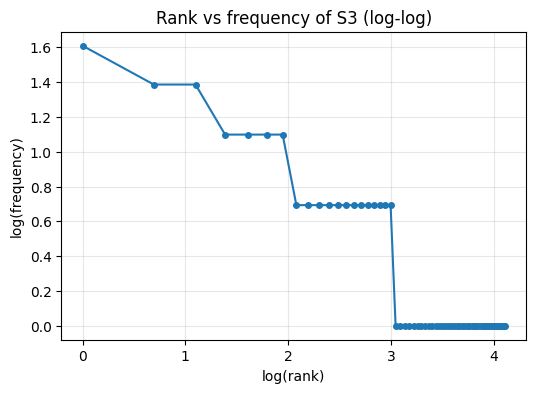

In [19]:
# log(rank) vs log(frequency) for S3
freq = sorted(Counter(S3).values(), reverse=True)
rank = np.arange(1, len(freq) + 1)

plt.figure(figsize=(6, 4))
plt.plot(np.log(rank), np.log(freq), "o-", markersize=4)
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Rank vs frequency of S3 (log-log)")
plt.grid(True, alpha=0.3)
plt.show()

In [20]:
# bigrams are counted inside each ticket so that a bigram never joins two different tickets
def top_bigrams(token_lists, n=5):
    c = Counter()
    for toks in token_lists:
        c.update(bigrams(toks))
    return c.most_common(n)

s1_lists = [[t.lower() for t in p["tokens"]] for p in all_pieces]
s3_lists = [[w.lower() for w in p["final"]] for p in all_pieces]

print("Top 5 bigrams of S1:")
for bg, c in top_bigrams(s1_lists):
    print("  %-30s %d" % (bg, c))

print()
print("Top 5 bigrams of S3:")
for bg, c in top_bigrams(s3_lists):
    print("  %-30s %d" % (bg, c))

Top 5 bigrams of S1:
  ('.', 'i')                     4
  ('i', 'do')                    3
  ('do', "n't")                  3
  ("n't", 'know')                3
  ('know', 'what')               3

Top 5 bigrams of S3:
  ("n't", 'know')                3
  ('know', 'changed')            3
  ('another', 'solution')        2
  ('unable', 'use')              2
  ('use', 'server')              2


## 6. Interpretation

The numbers in the answers below are filled in from my dataset by the code cell, so they match the output above.

In [21]:
t = summary
ttr = t["TTR"].tolist()

print("(a) Why does TTR change from S1 to S4?")
print(f"    TTR values: S1={ttr[0]}, S2={ttr[1]}, S3={ttr[2]}, S4={ttr[3]}")
print(f"    S1 to S2: {int(t.iloc[0,0] - t.iloc[1,0])} punctuation tokens were removed. Marks like '.' and ',' repeat a lot,")
print("    so removing them cuts the total tokens much more than the unique ones.")
print(f"    S2 to S3: stopwords (the, is, to ...) were removed. They are the most repeated words, so total tokens")
print(f"    fell from {int(t.iloc[1,0])} to {int(t.iloc[2,0])} while most of the unique content words stayed, and TTR went up.")
print(f"    S3 to S4: the total stays {int(t.iloc[3,0])} but stemming merges forms of a word, so unique tokens fell from")
print(f"    {int(t.iloc[2,1])} to {int(t.iloc[3,1])} and TTR went down.")
print()

# (b) example where the two tokenizers differ
print("(b) Example where word_tokenize and my_tokenize differ")
shown = False
for text in tickets + list(TEST_LINES):
    a, b = my_tokenize(text), word_tokenize(text)
    if a != b:
        mine = [x for x in a if x not in b]
        theirs = [x for x in b if x not in a]
        print("    text          :", text)
        print("    my_tokenize   :", mine)
        print("    word_tokenize :", theirs)
        print("    my pattern keeps these special items (contraction, email, url, phone, version) as one token,")
        print("    while word_tokenize applies Treebank rules and splits them at the punctuation inside them.")
        shown = True
        break
if not shown:
    print("    no difference found")
print()

# (c) stemming gone wrong
print("(c) Example where stemming gives an undesirable result")
bad = None
for _, r in full.iterrows():
    if r["porter"] != r["word"] and len(r["word"]) > 4 and not wn.synsets(r["porter"]):
        bad = r
        break
if bad is not None:
    print(f"    '{bad['word']}' -> Porter '{bad['porter']}', Lancaster '{bad['lancaster']}'")
    print(f"    '{bad['porter']}' is not a real word, so the stem is hard to read and can clash with other words.")
else:
    print("    no clear example found in this dataset")
print()

# (d) lemmatization better than stemming
print("(d) Example where POS-aware lemmatization keeps the meaning better than stemming")
good = None
for _, r in full.iterrows():
    if r["lemma"] != r["porter"] and r["lemma"] != r["word"] and wn.synsets(r["lemma"]):
        good = r
        break
if good is None:
    for _, r in full.iterrows():
        if r["lemma"] != r["porter"] and wn.synsets(r["lemma"]):
            good = r
            break
if good is not None:
    print(f"    '{good['word']}' (tag {good['pos']}) -> lemma '{good['lemma']}' but Porter gives '{good['porter']}'")
    print(f"    the lemma '{good['lemma']}' is a proper dictionary word with the right part of speech, the stem is just a cut-off form.")
else:
    print("    no clear example found in this dataset")

(a) Why does TTR change from S1 to S4?
    TTR values: S1=0.456, S2=0.5061, S3=0.663, S4=0.6196
    S1 to S2: 29 punctuation tokens were removed. Marks like '.' and ',' repeat a lot,
    so removing them cuts the total tokens much more than the unique ones.
    S2 to S3: stopwords (the, is, to ...) were removed. They are the most repeated words, so total tokens
    fell from 164 to 92 while most of the unique content words stayed, and TTR went up.
    S3 to S4: the total stays 92 but stemming merges forms of a word, so unique tokens fell from
    61 to 57 and TTR went down.

(b) Example where word_tokenize and my_tokenize differ
    text          : I can't login and I didn't change anything.
    my_tokenize   : ["can't", "didn't"]
    word_tokenize : ['ca', "n't", 'did', "n't"]
    my pattern keeps these special items (contraction, email, url, phone, version) as one token,
    while word_tokenize applies Treebank rules and splits them at the punctuation inside them.

(c) Example where 

    'changed' (tag VBN) -> lemma 'change' but Porter gives 'chang'
    the lemma 'change' is a proper dictionary word with the right part of speech, the stem is just a cut-off form.
